# From cell properties to element parameters

The elements of the sub-cellular element model are not biological objects. What one knows, or wants to
choose, are properties of the **cell**: its radius, how stiff it is and how fast it relaxes. The number of
elements $N$ used to represent it is a resolution setting and should not change those properties.

`scale_to_elements(cell, N)` in `cell_parameters.h` does this conversion, following
Sandersius & Newman, *Phys. Biol.* **5** (2008) 015002, section 2:

| | Relation | Paper |
|---|---|---|
| element spacing | $r_\mathrm{eq} = 2 R_\mathrm{cell}\,(p_3/N)^{1/3}$ | Eq. 8 |
| pair stiffness | $\kappa = \kappa_0\,N^{-1/3}\,(1 - \lambda N^{-1/3})$ | Eq. 11 |
| element drag | $\eta = \eta_0 / N$ | Eq. 12 |
| well depth | $u_0 = \kappa\,r_\mathrm{eq}^2 / (8\rho^2)$ | Eq. 5 |

$p_3$ is the packing density of the elements (default: close packing, $\pi/(3\sqrt2) \approx 0.74$) and
$\lambda = 0.75$ a correction the paper tunes for amorphous aggregates. The paper recommends $N \gtrsim 100$.

**Units.** Any consistent set works. This notebook uses micrometres, seconds and piconewtons, in which the
paper's cell is $R_\mathrm{cell} = 10$, $\kappa_0 = 5000$ pN/µm ($5\times10^{-3}$ N/m) and
$\eta_0 = 5000$ pN·s/µm ($5\times10^{-3}$ N·s/m). The ratio $\eta_0/\kappa_0 = 1$ s is the relaxation time of the cell.

**Three dimensions only.** The relations are derived for 3D; the code does not offer a 2D version.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

CELL = dict(radius=10.0, stiffness=5000.0, damping=5000.0)
CLOSE_PACKING = np.pi / (3.0 * np.sqrt(2.0))


def scale_to_elements(n, radius, stiffness, damping, steepness=2.0, packing_density=CLOSE_PACKING, scaling_correction=0.75):
    n = np.asarray(n, dtype=float)
    equilibrium_distance = 2.0 * radius * np.cbrt(packing_density / n)
    pair_stiffness = stiffness * n ** (-1 / 3) * (1.0 - scaling_correction * n ** (-1 / 3))
    return dict(
        equilibrium_distance=equilibrium_distance,
        pair_stiffness=pair_stiffness,
        drag_coefficient=damping / n,
        intra_well_depth=pair_stiffness * equilibrium_distance**2 / (8.0 * steepness**2),
    )

## Check against the C++ implementation

`data/scaled_cell_N.csv` is the output of the `scaled_cell` example, which builds the paper's cell from $N$
elements and lets it relax. Its header lists the element parameters the C++ code derived:

```bash
for n in 64 128 256 512 1024; do
  build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.scaled_cell $n 2 6 24 \
      > mechanics/micromechanics/docs/notebooks/data/scaled_cell_$n.csv
done
```

In [2]:
element_counts = [64, 128, 256, 512, 1024]


def load(n):
    file = Path("data") / f"scaled_cell_{n}.csv"
    header = file.read_text().splitlines()[0]
    params = {key: float(value) for key, value in (item.split("=") for item in header.lstrip("# ").split())}
    table = np.genfromtxt(file, delimiter=",", names=True, skip_header=1)
    return params, table


runs = {n: load(n) for n in element_counts}

for n, (params, _) in runs.items():
    expected = scale_to_elements(n, **CELL, steepness=params["steepness"])
    for name, value in expected.items():
        np.testing.assert_allclose(params[name], value, rtol=1e-12, err_msg=f"{name} for N = {n}")

print("Python formulas agree with the C++ parameters for N =", element_counts)
print(f"N = 256 gives r_eq = {runs[256][0]['equilibrium_distance']:.3f} um; the paper quotes 2.85 um.")

Python formulas agree with the C++ parameters for N = [64, 128, 256, 512, 1024]
N = 256 gives r_eq = 2.850 um; the paper quotes 2.85 um.


## How the element parameters change with resolution

More elements are smaller, each pair is softer, and each element is dragged less. The last panel is the
largest forward-Euler timestep for an isolated pair, $\eta/\kappa$ (see `pair_potential.ipynb`): it shrinks
roughly as $N^{-2/3}$, so doubling the resolution costs more than twice the work per unit of simulated time.

     N     r_eq     kappa       eta        u0   eta/kappa
    64    4.523    1015.6     78.12     649.4      0.0769
   128    3.590     844.5     39.06     340.2      0.0463
   256    2.850     694.4     19.53     176.2      0.0281
   512    2.262     566.4      9.77      90.5      0.0172
  1024    1.795     459.2      4.88      46.2      0.0106


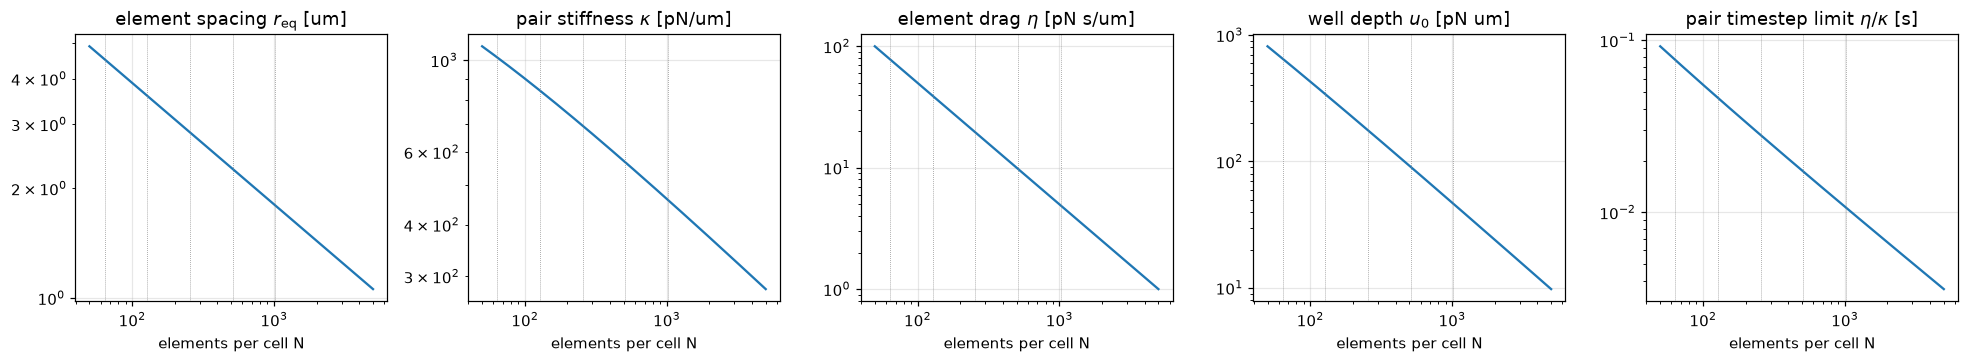

In [3]:
n = np.logspace(np.log10(50), np.log10(5000), 200)
scaled = scale_to_elements(n, **CELL)

panels = [
    (scaled["equilibrium_distance"], r"element spacing $r_\mathrm{eq}$ [um]"),
    (scaled["pair_stiffness"], r"pair stiffness $\kappa$ [pN/um]"),
    (scaled["drag_coefficient"], r"element drag $\eta$ [pN s/um]"),
    (scaled["intra_well_depth"], r"well depth $u_0$ [pN um]"),
    (scaled["drag_coefficient"] / scaled["pair_stiffness"], r"pair timestep limit $\eta/\kappa$ [s]"),
]

fig, axes = plt.subplots(1, len(panels), figsize=(18, 3.4))
for ax, (values, label) in zip(axes, panels):
    ax.loglog(n, values)
    ax.set(xlabel="elements per cell N", title=label)
    for count in element_counts:
        ax.axvline(count, color="gray", linewidth=0.5, linestyle=":")
fig.tight_layout()

print(f"{'N':>6}{'r_eq':>9}{'kappa':>10}{'eta':>10}{'u0':>10}{'eta/kappa':>12}")
for count in element_counts:
    s = scale_to_elements(count, **CELL)
    print(f"{count:>6}{s['equilibrium_distance']:>9.3f}{s['pair_stiffness']:>10.1f}{s['drag_coefficient']:>10.2f}"
          f"{s['intra_well_depth']:>10.1f}{s['drag_coefficient'] / s['pair_stiffness']:>12.4f}")

## Does the cell come out the requested size?

This is the test of the scaling. $N$ elements are scattered at random in a ball of the requested radius
(10 µm) and relax for 6 s with the solver. The size of the cell is measured as $\sqrt{5/3}$ times the radius
of gyration, which is the radius of a uniform ball with the same spread of elements.

     N    radius   vs requested   largest speed
    64     9.449          -5.5%           0.511
   128     9.323          -6.8%           0.118
   256     9.287          -7.1%           0.106
   512     9.208          -7.9%           0.704
  1024     9.172          -8.3%           0.794


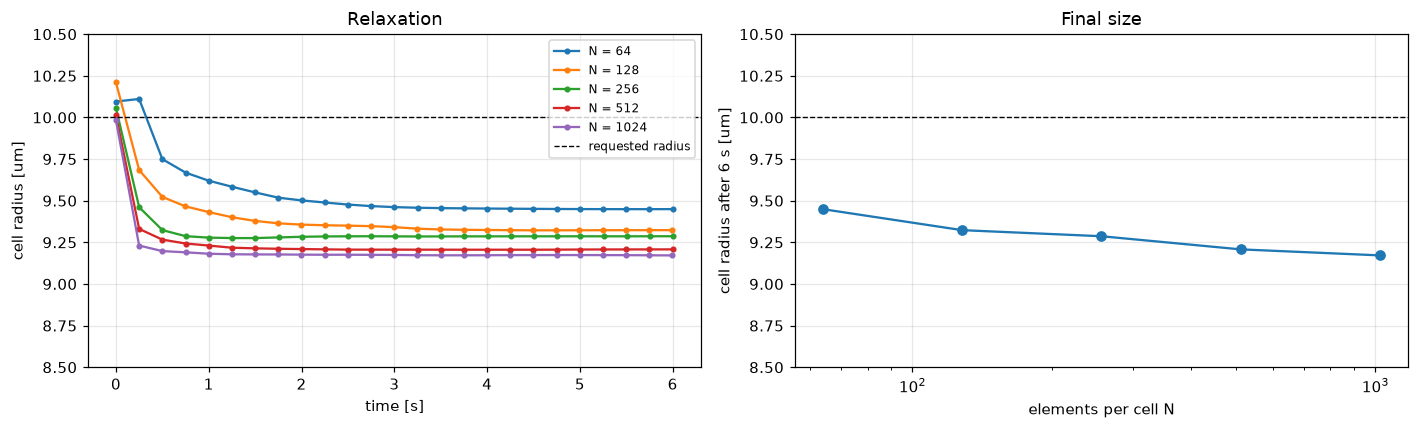

In [4]:
fig, (ax_time, ax_final) = plt.subplots(1, 2, figsize=(13, 4))

final_radius = {}
for count in element_counts:
    params, table = runs[count]
    ax_time.plot(table["time"], table["radius_from_gyration"], marker=".", label=f"N = {count}")
    final_radius[count] = table["radius_from_gyration"][-1]

ax_time.axhline(CELL["radius"], color="black", linestyle="--", linewidth=0.9, label="requested radius")
ax_time.set(xlabel="time [s]", ylabel="cell radius [um]", title="Relaxation", ylim=(8.5, 10.5))
ax_time.legend(fontsize=8)

ax_final.semilogx(list(final_radius), list(final_radius.values()), marker="o")
ax_final.axhline(CELL["radius"], color="black", linestyle="--", linewidth=0.9)
ax_final.set(xlabel="elements per cell N", ylabel="cell radius after 6 s [um]", title="Final size", ylim=(8.5, 10.5))
fig.tight_layout()

print(f"{'N':>6}{'radius':>10}{'vs requested':>15}{'largest speed':>16}")
for count in element_counts:
    table = runs[count][1]
    print(f"{count:>6}{final_radius[count]:>10.3f}{100 * (final_radius[count] / CELL['radius'] - 1):>14.1f}%{table['largest_speed'][-1]:>16.3g}")

In [5]:
resolved = [final_radius[count] for count in element_counts if count >= 128]

assert all(abs(radius - CELL["radius"]) < 1.0 for radius in resolved), "cells of 128 or more elements must be within 10% of the requested radius"
assert max(resolved) - min(resolved) < 0.3, "the size must not depend on the number of elements"

print(f"N >= 128: radius between {min(resolved):.2f} and {max(resolved):.2f} um for a requested {CELL['radius']:.0f} um.")

N >= 128: radius between 9.17 and 9.32 um for a requested 10 um.


## Reading the result

- **The size does not depend on the resolution.** From 128 to 1024 elements the element spacing shrinks by
  half, yet the cell radius changes by less than 2%.
- **The cell is a little smaller than requested**, by about 7–8%. The paper explains why: with $\rho = 2$
  the attraction reaches beyond nearest neighbours while the repulsion is soft, so the aggregate compresses
  itself and elements sit slightly closer than $r_\mathrm{eq}$. If the exact radius matters, request a
  slightly larger one or lower the packing density.
- **A small trend remains:** the radius falls slowly with resolution, from 9.32 at 128 elements to 9.17 at
  1024. It is within 2%, but it is systematic, not scatter.
- **Finer cells settle faster here.** This relaxation is elements pushing apart locally, which happens on the
  pair time scale $\eta/\kappa$ and therefore speeds up with $N$. It is not the relaxation time of the whole
  cell, $\eta_0/\kappa_0$, which the paper shows to be independent of $N$ and which this run does not probe.
- **64 elements is below the recommended resolution**, as the paper says; it is shown for comparison.

### Caveats

- **Starting positions matter for stiffer potentials.** The elements here start at random positions, so some
  pairs overlap strongly. With $\rho = 2$ they simply push apart. In exploratory runs with $\rho = 4$ the
  much harder core threw elements out beyond the cutoff, where nothing pulls them back, and the cell did not
  recover within 8 s. A stiff potential needs elements placed without strong overlaps (for example on a
  lattice at spacing $r_\mathrm{eq}$).
- **Only the size is checked here.** Whether the stiffness and relaxation time of the cell are independent of
  $N$, which is the main claim of the paper, needs a deformation test (applying a force and measuring strain)
  that the model cannot do yet because it has no external forces.
- **No thermal noise**, so the aggregates are frozen in whatever packing they relax into.